Question 69. For Q67's decision tree, plot accuracy against tree depth.

Original dataset:


,ID,Age,Income,Spending Score,Region,Category,Visits,Online Time,Purchase,Rating
0,1,22,25000,65,North,Grocery,5,12,Yes,4.2
1,2,35,55000,40,West,Electronics,2,8,No,3.8
2,3,28,32000,70,South,Clothing,6,15,Yes,4.5
3,4,45,75000,30,East,Grocery,3,6,No,3.5
4,5,30,60000,80,South,Electronics,7,18,Yes,4.8
5,6,26,40000,55,North,Clothing,4,10,Yes,4.1
6,7,38,50000,45,West,Grocery,3,9,No,3.9
7,8,29,45000,75,South,Electronics,6,16,Yes,4.6
8,9,50,80000,35,West,Clothing,2,5,No,3.6
9,10,33,52000,60,North,Grocery,5,11,Yes,4.3


Selected depth: 1; untouched test accuracy: 1.000


,Depth,TrainingAccuracy,ValidationAccuracy
0,1,1.0,0.583333
1,2,1.0,0.583333
2,3,1.0,0.583333
3,4,1.0,0.583333
4,5,1.0,0.583333
5,6,1.0,0.583333


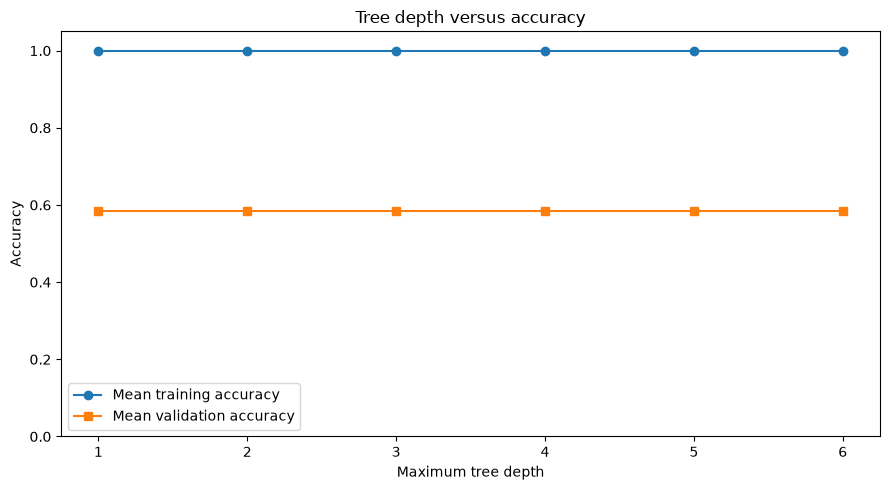

Saved question69_plot.png


In [1]:
# Step 1: Import the libraries needed for this program.
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# Step 2: Load the CSV file from this question's folder into a DataFrame (table).
df = pd.read_csv("Customer_PurchaseData.csv")
print("Original dataset:")
display(df)

# Step 3: Select the same predictors and outcome used in Q67.
X = df.drop(columns=["ID", "Purchase", "Rating"])
y = df["Purchase"]

# Step 4: List numeric and categorical predictors.
numeric = ["Age", "Income", "Spending Score", "Visits", "Online Time"]
categorical = ["Region", "Category"]

# Step 5: Keep the final test rows separate from depth selection.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Step 6: Define the feature encoding.
preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric),
    ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
])



# Step 7: Create two repeatable stratified validation folds inside the training set.
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

# Step 8: Compare training and validation accuracy at maximum depths 1 through 6.
scores = []
for depth in range(1, 7):
    model = Pipeline([("preprocess", clone(preprocessor)),
                      ("classifier", DecisionTreeClassifier(max_depth=depth, random_state=42))])
    evaluation = cross_validate(model, X_train, y_train, cv=cv, scoring="accuracy",
                                return_train_score=True)
    scores.append({"Depth": depth, "TrainingAccuracy": evaluation["train_score"].mean(),
                   "ValidationAccuracy": evaluation["test_score"].mean()})

# Step 9: Select the shallowest depth with the highest mean validation accuracy.
scores = pd.DataFrame(scores)
best_depth = int(scores.loc[scores["ValidationAccuracy"].idxmax(), "Depth"])

# Step 10: Fit the selected model on all training rows and evaluate the untouched test set.
final_model = Pipeline([("preprocess", clone(preprocessor)),
                        ("classifier", DecisionTreeClassifier(max_depth=best_depth, random_state=42))])
final_model.fit(X_train, y_train)
print(f"Selected depth: {best_depth}; untouched test accuracy: {final_model.score(X_test, y_test):.3f}")

# Step 11: Plot both accuracy curves and save the depth comparison.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(scores["Depth"], scores["TrainingAccuracy"], "o-", label="Mean training accuracy")
ax.plot(scores["Depth"], scores["ValidationAccuracy"], "s-", label="Mean validation accuracy")
ax.set(xlabel="Maximum tree depth", ylabel="Accuracy", ylim=(0, 1.05), title="Tree depth versus accuracy")
ax.legend()
display(scores)
scores.to_csv("depth_accuracy.csv", index=False)

# Final step: Arrange labels, save the chart and display it below this cell.
fig.tight_layout()
fig.savefig("question69_plot.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved question69_plot.png")


Interpretation / method

ID is an identifier and is excluded. Rating is also excluded because it may only be known after a purchase; this avoids potential target leakage. Categorical encoding is fitted only on the training data. The fixed, stratified split has seven training and three test rows; accuracy on three rows is only an illustration, not reliable evidence of generalisation. Depth is compared with two-fold stratified cross-validation within training data, keeping the final test rows out of model selection. Each fold fits its own encoder.